In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [11]:
file_path = r"C:\Users\janfr\OneDrive - Delft University of Technology\Bestanden van Chris van Bodegom - TIL6022 Groep 14\traindata_filtered_2024.csv"

# Load the dataset
datas = pd.read_csv(file_path, low_memory=False)

# Preview the first 5 rows to confirm it loaded
datas.head()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,12719194,2024-01-06,Intercity,NS,22401,False,False,0,114586491,UT,Utrecht Centraal,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,9,9
1,12719194,2024-01-06,Intercity,NS,22401,False,False,0,114586492,AMF,Amersfoort Centraal,2024-01-06T02:14:00+01:00,0.0,False,NaN,NaN,NaN,False,2,2
2,12719195,2024-01-06,Intercity,NS,22201,False,False,1,114586493,HLM,Haarlem,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,1,1
3,12719195,2024-01-06,Intercity,NS,22201,False,False,0,114586494,ASD,Amsterdam Centraal,2024-01-06T02:13:00+01:00,1.0,False,NaN,NaN,NaN,False,7a,7a
4,12719196,2024-01-06,Intercity,NS,1410,False,False,0,114586495,RTD,Rotterdam Centraal,NaN,NaN,NaN,2024-01-06T02:00:00+01:00,0.0,False,False,7,7


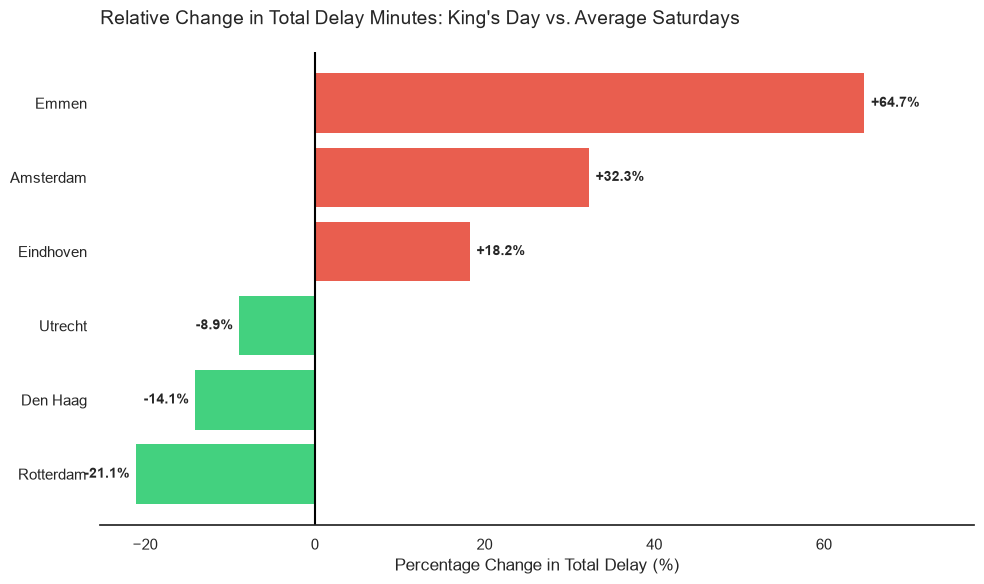

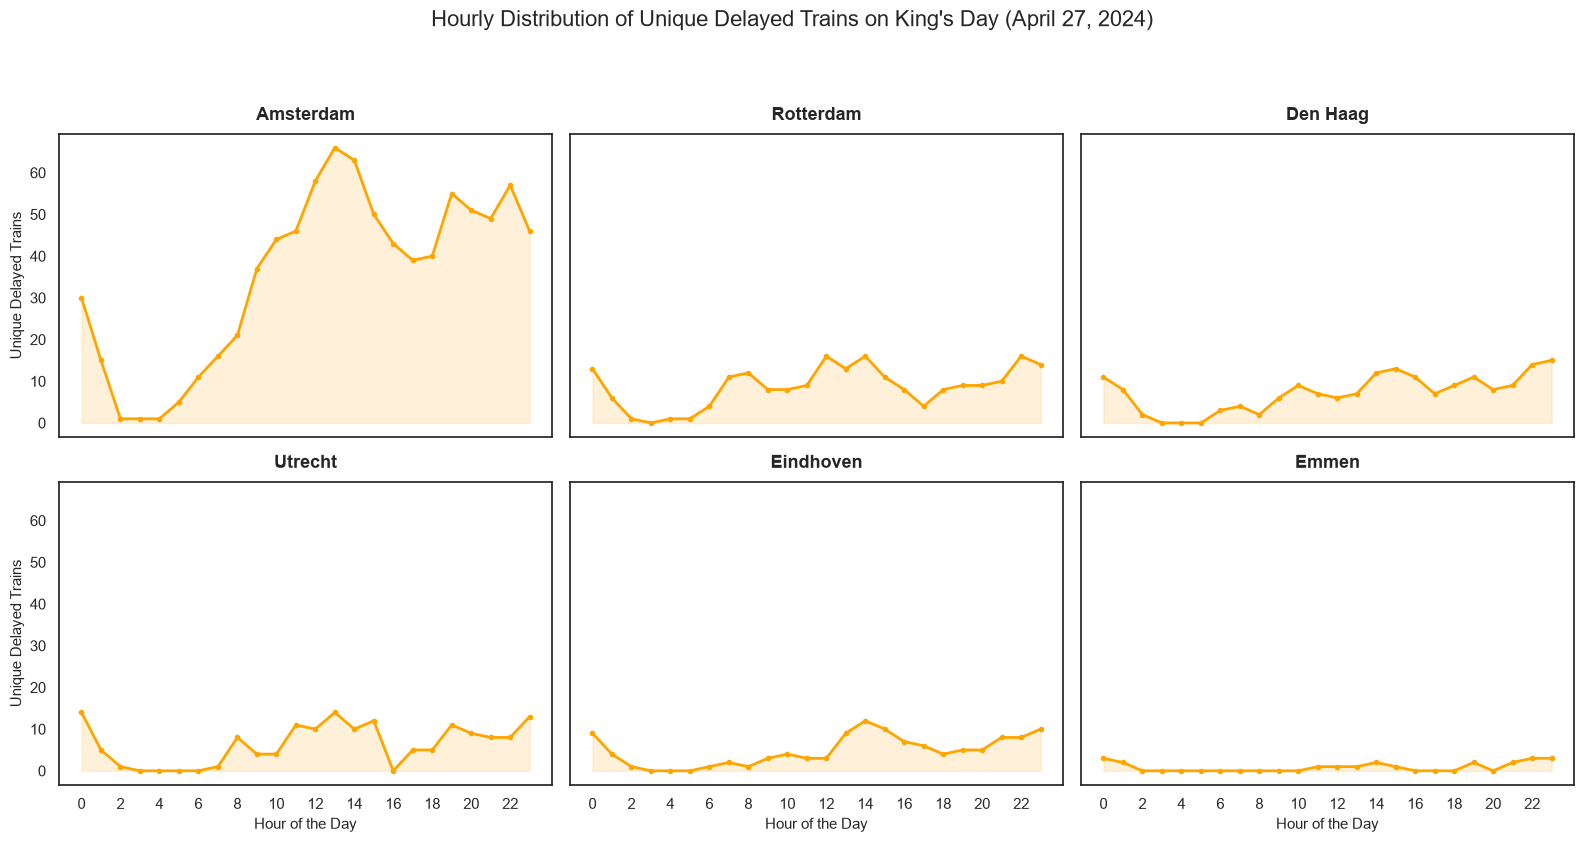

In [ ]:

# 1. SHARED SETUP & DATA PREPARATION


target_stations = [
    #Amstedram
    "Amsterdam Bijlmer ArenA", "Amsterdam Centraal", "Amsterdam Holendrecht", 
    "Amsterdam Lelylaan", "Amsterdam Muiderpoort", "Amsterdam RAI", 
    "Amsterdam Science Park", "Amsterdam Sloterdijk", "Amsterdam Zuid",
    #Rotterdam
    "Rotterdam Alexander", "Rotterdam Blaak", "Rotterdam Centraal", 
    "Rotterdam Lombardijen", "Rotterdam Noord", "Rotterdam Zuid",
    #Den-Haag
    "Den Haag Centraal", "Den Haag HS", "Den Haag Laan v NOI", 
    "Den Haag Mariahoeve", "Den Haag Moerwijk", "Den Haag Ypenburg",
    #Additions
    "Utrecht Centraal", "Eindhoven Centraal", "Emmen", "Emmen Zuid"
]

# Shared function to map stations to their parent cities
def get_parent_city(station_name):
    if station_name.startswith("Amsterdam"): return "Amsterdam"
    if station_name.startswith("Rotterdam"): return "Rotterdam"
    if station_name.startswith("Den Haag"): return "Den Haag"
    if station_name.startswith("Utrecht"): return "Utrecht"
    if station_name.startswith("Eindhoven"): return "Eindhoven"
    if station_name.startswith("Emmen"): return "Emmen"
    return "Other"



# 2. FIGURE 1: RELATIVE % CHANGE CHART


# Filter dataset and map to parent cities
df_fig1 = datas[datas['Stop:Station name'].isin(target_stations)].copy()
df_fig1['Stop:Arrival delay'] = pd.to_numeric(df_fig1['Stop:Arrival delay'], errors='coerce').fillna(0.0)
df_fig1['City'] = df_fig1['Stop:Station name'].apply(get_parent_city)

# Classify dates: King's Day vs. Other saturdays
df_fig1['Day Type'] = np.where(
    df_fig1['Service:Date'] == '2024-04-27', 
    "King's Day", 
    "Baseline"
)

# Calculate total daily delays per city, then average those totals by day type
daily_totals = df_fig1.groupby(['City', 'Service:Date', 'Day Type'])['Stop:Arrival delay'].sum().reset_index()
city_delays = daily_totals.groupby(['City', 'Day Type'])['Stop:Arrival delay'].mean().unstack()

# Calculate the Percentage Change and Sort
city_delays['% Change'] = ((city_delays["King's Day"] - city_delays["Baseline"]) / city_delays["Baseline"]) * 100
plot_data = city_delays.reset_index()
plot_data = plot_data.sort_values(by='% Change', ascending=True)

# Define conditional colors (Red for > 0, Green for <= 0)
colors = ['#E74C3C' if val > 0 else '#2ECC71' for val in plot_data['% Change']]

# Plotting the Horizontal Chart
plt.figure(figsize=(10, 6))
sns.set_theme(style="white")

bars = plt.barh(plot_data['City'], plot_data['% Change'], color=colors, edgecolor='none', alpha=0.9)
plt.axvline(0, color='black', linewidth=1.5)

for bar in bars:
    xval = bar.get_width()
    yval = bar.get_y() + bar.get_height() / 2
    
    offset = 5 if xval > 0 else -5
    ha = 'left' if xval > 0 else 'right'
    
    plt.annotate(
        f'{xval:+.1f}%', 
        (xval, yval),
        ha=ha, va='center',
        fontsize=10, fontweight='bold',
        xytext=(offset, 0), textcoords='offset points'
    )

plt.title("Relative Change in Total Delay Minutes: King's Day vs. Average Saturdays", fontsize=14, pad=20, loc='left')
plt.xlabel("Percentage Change in Total Delay (%)", fontsize=12)
plt.ylabel("") 
sns.despine(left=True, bottom=False)
plt.xlim(plot_data['% Change'].min() * 1.2, plot_data['% Change'].max() * 1.2)

plt.tight_layout()
plt.show()



# 3. FIGURE 2: HOURLY DISTRIBUTION GRID


# Filter King's Day and map the cities
kings_day_data = datas[
    (datas['Service:Date'] == '2024-04-27') & 
    (datas['Stop:Station name'].isin(target_stations))
].copy()

kings_day_data['City'] = kings_day_data['Stop:Station name'].apply(get_parent_city)

# Clean delays and isolate actual delayed trains
kings_day_data['Stop:Arrival delay'] = pd.to_numeric(kings_day_data['Stop:Arrival delay'], errors='coerce').fillna(0)
delayed_trains = kings_day_data[kings_day_data['Stop:Arrival delay'] > 0].copy()

# Extract the Hour
delayed_trains['Stop:Arrival time'] = pd.to_datetime(delayed_trains['Stop:Arrival time'], errors='coerce')
delayed_trains['Hour'] = delayed_trains['Stop:Arrival time'].dt.hour.astype('Int64')
delayed_trains = delayed_trains.dropna(subset=['Hour'])

# Count Unique Delayed Trains per Hour per City
hourly_distribution = (
    delayed_trains.groupby(['City', 'Hour'])['Service:Train number']
    .nunique()
    .reset_index(name='Unique Delayed Trains')
)


cities = ['Amsterdam', 'Rotterdam', 'Den Haag', 'Utrecht', 'Eindhoven', 'Emmen']
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
axes = axes.flatten()
sns.set_theme(style="whitegrid")

for i, city in enumerate(cities):
    ax = axes[i]
    
    # Isolate city data and ensure all 24 hours exist
    city_data = hourly_distribution[hourly_distribution['City'] == city]
    all_hours = pd.DataFrame({'Hour': range(24)})
    city_data = pd.merge(all_hours, city_data, on='Hour', how='left').fillna(0)
    
    x = city_data['Hour']
    y = city_data['Unique Delayed Trains']
    
    ax.plot(x, y, color='orange', marker='.', linewidth=2, label="Delayed Trains")
    ax.fill_between(x, y, color='orange', alpha=0.15)
    
    # Formatting
    ax.set_title(city, fontsize=13, fontweight='bold', pad=10)
    ax.set_xticks(range(0, 24, 2)) 
    
    if i >= 3: ax.set_xlabel("Hour of the Day", fontsize=11)
    if i % 3 == 0: ax.set_ylabel("Unique Delayed Trains", fontsize=11)

plt.suptitle("Hourly Distribution of Unique Delayed Trains on King's Day (April 27, 2024)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()